In [1]:
from anemone.system import Loop, Receiver
from anemone.forwards import Forward
from anemone.physics import dbdt_center_of_circular_loop_halfspace
from anemone.experiment import plot_error_statistics

import matplotlib.pyplot as plt

import torch
import numpy as np

## Center of a Circular Loop at the surface of a homogeneous halfspace.

In [27]:
tx = Loop.circle(1)
rx = Receiver()
t  = torch.logspace(-9, 0, 91)


fwr = Forward(tx, rx, t)

In [28]:
rho = torch.logspace(0., 3., 1000)

In [29]:
dbdt = fwr(rho)
dbdt_analytic = dbdt_center_of_circular_loop_halfspace(t, rho, tx.radius)
dbdt_abserr = dbdt-dbdt_analytic
dbdt_relerr = torch.abs(dbdt_abserr / dbdt_analytic)*100.

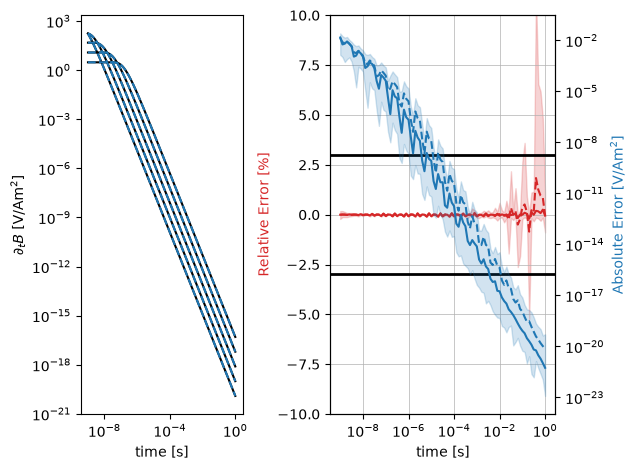

In [31]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(fwr.times, dbdt_analytic[::200].T, 'k-')
axs[0].loglog(fwr.times, dbdt[::200].T, 'C0--')
axs[0].set_ylabel('$\\partial_tB$ [V/Am$^2$]')
axs[0].set_xlabel('time [s]')
axs[0].set_aspect('equal')

ax1,ax2=plot_error_statistics(fwr.times, dbdt, dbdt_analytic, log_relerr=False, ax=axs[1])
ax2.set_ylabel('Absolute Error [V/Am$^2$]');
ax1.set_ylim(-10, 10)
plt.tight_layout()

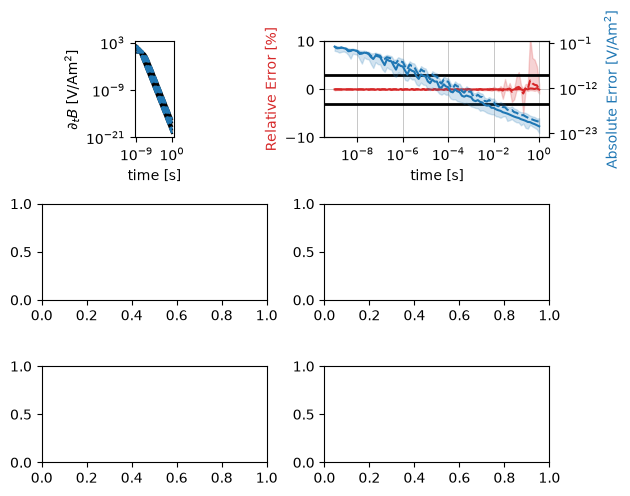

In [32]:
fig,axs = plt.subplots(3,2)
axs[0, 0].loglog(fwr.times, dbdt_analytic[::200].T, 'k-')
axs[0, 0].loglog(fwr.times, dbdt[::200].T, 'C0--')
axs[0, 0].set_ylabel('$\\partial_tB$ [V/Am$^2$]')
axs[0, 0].set_xlabel('time [s]')
axs[0, 0].set_aspect('equal')

ax1,ax2=plot_error_statistics(fwr.times, dbdt, dbdt_analytic, log_relerr=False, ax=axs[0, 1])
ax2.set_ylabel('Absolute Error [V/Am$^2$]');
ax1.set_ylim(-10, 10)
plt.tight_layout()